# DQN Atari: Silver's Hyperparameter Experiments

**Member:** Nshuti Shalom Silver Jr (Member 2: replay buffer, epsilon-greedy, Bellman update, target network)

This notebook runs my ten hyperparameter experiments for our group's Deep Q-Network (DQN) on Atari Q*bert (`ALE/Qbert-v5`).

It follows the same workflow as Hikma's notebook so that our results are comparable:

- The group's own code from GitHub (`train.py`, `dqn.py`, `dqn_agent.py`, `replay_buffer.py`, `environment.py`).
- 100,000 environment steps per experiment, seed 42.
- Greedy evaluation (epsilon = 0) over 10 episodes per model, seeds 42 to 51.
- Everything is saved to Google Drive, so a disconnected session loses nothing.

**Before running:** `Runtime > Change runtime type > T4 GPU`.

**Run the cells from top to bottom.** After a disconnect, run them from the top again: finished experiments are skipped.

# 1. Check the GPU

In [1]:
# [colab-setup]
!nvidia-smi

import platform
import torch

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Use Runtime > Change runtime type > T4 GPU.")

Fri Nov 13 10:55:56 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   34C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

# 2. Connect Google Drive

Colab's own storage is temporary. Models, logs and plots are written to Google Drive so they survive a disconnect.

In [3]:
# [colab-setup]
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [4]:
from pathlib import Path

# My identity for folder names and experiment IDs.
MEMBER = "silver"
MEMBER_FULL_NAME = "Nshuti Shalom Silver Jr"

# Everything from this notebook is stored here.
DRIVE_ROOT = Path("/content/drive/MyDrive/dqn-experiments-silver")
WORK_DIR = Path("/content")

In [5]:
MODELS_DIR = DRIVE_ROOT / "models" / MEMBER
RESULTS_DIR = DRIVE_ROOT / "results" / MEMBER
PLOTS_DIR = DRIVE_ROOT / "plots" / MEMBER
CONFIG_DIR = DRIVE_ROOT / "configs"

for folder in (MODELS_DIR, RESULTS_DIR, PLOTS_DIR, CONFIG_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Member:", MEMBER)
print("Storage location:", DRIVE_ROOT)


def run_and_show(command, extra_env=None):
    """Run a command and print its output line by line as it happens."""
    import os
    import subprocess

    process = subprocess.Popen(
        command,
        stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True,
        env={**os.environ, **(extra_env or {})},
    )
    for line in process.stdout:
        print(line, end="", flush=True)
    process.wait()
    if process.returncode != 0:
        raise RuntimeError(f"Command failed: {' '.join(map(str, command))}")

Member: silver
Storage location: /content/drive/MyDrive/dqn-experiments-silver


# 3. Get the group project from GitHub

We use the integrated version on the `main` branch, the same code the rest of the group trained with. The commit ID is recorded so the exact version is known.

In [6]:
# [colab-setup]
import os
import subprocess

REPO_URL = "https://github.com/Hikma-codes/Formative-3---DQN-Atari-Project.git"
REPO_DIR = Path("/content/Formative-3---DQN-Atari-Project")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
else:
    print("Repository already exists. Reusing it.")

os.chdir(REPO_DIR)

REPO_COMMIT = subprocess.run(
    ["git", "rev-parse", "--short", "HEAD"],
    capture_output=True, text=True, check=True,
).stdout.strip()

print("Project directory:", os.getcwd())
print("Commit:", REPO_COMMIT)

required_files = [
    "train.py", "dqn.py", "dqn_agent.py", "replay_buffer.py", "environment.py",
]
missing = [name for name in required_files if not (REPO_DIR / name).exists()]
assert not missing, f"Missing from the repository: {missing}"
print("All required project files are present.")

Project directory: /content/Formative-3---DQN-Atari-Project
Commit: 943cbc0
All required project files are present.


# 4. Install dependencies with uv

`uv sync --frozen` installs the exact package versions from the group's `uv.lock`. This takes a few minutes the first time.

In [7]:
# [colab-setup]
!curl -LsSf https://astral.sh/uv/install.sh | sh

os.environ["PATH"] = "/root/.local/bin:" + os.environ["PATH"]

!uv --version
!uv sync --frozen

downloading uv 0.13.8 x86_64-unknown-linux-gnu
installing to /usr/local/bin
  uv
  uvx
everything's installed!
uv 0.13.8 (x86_64-unknown-linux-gnu)
Using CPython 3.13.16 interpreter at: /usr/bin/python3
Creating virtual environment at: .venv
Prepared 45 packages in 1m 19s
Installed 45 packages in 511ms
 + ale-py==0.12.1
 + cloudpickle==3.1.2
 + contourpy==1.4.0
 + cuda-bindings==13.5.0
 + cuda-pathfinder==1.8.6
 + cuda-toolkit==13.2.2
 + cycler==0.12.1
 + farama-notifications==0.0.6
 + filelock==4.2.10
 + fonttools==4.68.0
 + fsspec==2026.9.0
 + gymnasium==1.4.0
 + jinja2==3.1.6
 + kiwisolver==1.5.1
 + markupsafe==3.0.4
 + matplotlib==3.11.2
 + mpmath==1.3.0
 + networkx==3.7
 + numpy==2.5.4
 + nvidia-cublas==13.4.1.3
 + nvidia-cuda-cccl==13.3.5.0.6
 + nvidia-cuda-cupti==13.2.86
 + nvidia-cuda-nvrtc==13.2.86
 + nvidia-cuda-runtime==13.2.86
 + nvidia-cudnn-cu13==9.26.0.51
 + nvidia-cufft==12.2.0.57
 + nvidia-cufile==1.17.1.22
 + nvidia-cusolver==12.2.0.11
 + nvidia-cusparse==12.7.10.12
 

In [8]:
# [colab-setup]
# All training and evaluation runs inside the uv environment.
PYTHON_CMD = ["uv", "run", "python"]
REQUIRE_GPU = True

subprocess.run(
    PYTHON_CMD + [
        "-c",
        "import torch; "
        "print('PyTorch version:', torch.__version__); "
        "assert torch.cuda.is_available(), 'CUDA is unavailable in the uv environment'; "
        "print('GPU:', torch.cuda.get_device_name(0))",
    ],
    check=True,
)

CompletedProcess(args=['uv', 'run', 'python', '-c', "import torch; print('PyTorch version:', torch.__version__); assert torch.cuda.is_available(), 'CUDA is unavailable in the uv environment'; print('GPU:', torch.cuda.get_device_name(0))"], returncode=0)

# 5. My ten hyperparameter configurations

Baseline (same as the group's): learning rate 1e-4, gamma 0.99, batch size 32, epsilon 1.0 to 0.1 over 100,000 steps.

- **EXP01** is my own baseline (control) run on this GPU.
- **EXP02 to EXP08** change one hyperparameter each, using values nobody in the group has tried yet.
- **EXP09 and EXP10** combine several changes. They can be edited here before they are trained.

`epsilon_decay` is the number of environment steps over which epsilon falls linearly from start to end.

In [23]:
import json

BASELINE = {
    "learning_rate": 1e-4,
    "gamma": 0.99,
    "batch_size": 32,
    "epsilon_start": 1.0,
    "epsilon_end": 0.1,
    "epsilon_decay": 100_000,
}

# (experiment number, changes from the baseline, what the experiment tests)
EXPERIMENT_PLAN = [
    (1, {}, "Baseline (control run)"),
    (2, {"learning_rate": 5e-4}, "High learning rate"),
    (3, {"gamma": 0.90}, "Low gamma (short-sighted agent)"),
    (4, {"gamma": 0.999}, "Very high gamma (far-sighted agent)"),
    (5, {"batch_size": 256}, "Large batch size"),
    (6, {"epsilon_end": 0.01}, "Very low final epsilon"),
    (7, {"epsilon_decay": 25_000}, "Fast epsilon decay"),
    (8, {"epsilon_start": 0.5}, "Low starting epsilon"),
        (9, {"batch_size": 256, "gamma": 0.97},
        "Large batch + gamma 0.97"),
    (10, {"batch_size": 256, "gamma": 0.97, "learning_rate": 2e-4},
        "Large batch + gamma 0.97 + learning rate 2e-4"),
]

HYPERPARAMETERS = list(BASELINE)

EXPERIMENTS = []
DESCRIPTIONS = {}

for number, changes, description in EXPERIMENT_PLAN:
    experiment_id = f"{MEMBER.upper()}_EXP{number:02d}"
    EXPERIMENTS.append({
        "experiment_id": experiment_id,
        "member": MEMBER,
        **BASELINE,
        **changes,
    })
    DESCRIPTIONS[experiment_id] = description

# Checks: ten experiments, unique IDs, ten different combinations, my name.
experiment_ids = [e["experiment_id"] for e in EXPERIMENTS]
combinations = {tuple(e[h] for h in HYPERPARAMETERS) for e in EXPERIMENTS}

assert len(EXPERIMENTS) == 10, "Expected exactly 10 experiments."
assert len(set(experiment_ids)) == 10, "Duplicate experiment IDs found."
assert len(combinations) == 10, "Two experiments use the same combination."
assert all(e["member"] == MEMBER for e in EXPERIMENTS)

CONFIG_FILE = CONFIG_DIR / f"{MEMBER}_experiments.json"
CONFIG_FILE.write_text(json.dumps(EXPERIMENTS, indent=2) + "\n", encoding="utf-8")

for e in EXPERIMENTS:
    print(
        e["experiment_id"],
        "| lr:", e["learning_rate"],
        "| gamma:", e["gamma"],
        "| batch:", e["batch_size"],
        "| epsilon:", e["epsilon_start"], "->", e["epsilon_end"],
        "| decay:", e["epsilon_decay"],
        "|", DESCRIPTIONS[e["experiment_id"]],
    )

print("\nConfiguration saved to:", CONFIG_FILE)

SILVER_EXP01 | lr: 0.0001 | gamma: 0.99 | batch: 32 | epsilon: 1.0 -> 0.1 | decay: 100000 | Baseline (control run)
SILVER_EXP02 | lr: 0.0005 | gamma: 0.99 | batch: 32 | epsilon: 1.0 -> 0.1 | decay: 100000 | High learning rate
SILVER_EXP03 | lr: 0.0001 | gamma: 0.9 | batch: 32 | epsilon: 1.0 -> 0.1 | decay: 100000 | Low gamma (short-sighted agent)
SILVER_EXP04 | lr: 0.0001 | gamma: 0.999 | batch: 32 | epsilon: 1.0 -> 0.1 | decay: 100000 | Very high gamma (far-sighted agent)
SILVER_EXP05 | lr: 0.0001 | gamma: 0.99 | batch: 256 | epsilon: 1.0 -> 0.1 | decay: 100000 | Large batch size
SILVER_EXP06 | lr: 0.0001 | gamma: 0.99 | batch: 32 | epsilon: 1.0 -> 0.01 | decay: 100000 | Very low final epsilon
SILVER_EXP07 | lr: 0.0001 | gamma: 0.99 | batch: 32 | epsilon: 1.0 -> 0.1 | decay: 25000 | Fast epsilon decay
SILVER_EXP08 | lr: 0.0001 | gamma: 0.99 | batch: 32 | epsilon: 0.5 -> 0.1 | decay: 100000 | Low starting epsilon
SILVER_EXP09 | lr: 0.0001 | gamma: 0.97 | batch: 256 | epsilon: 1.0 -> 0.

# 6. Test the implementation

Checks the CNN and the learning logic (replay buffer, epsilon-greedy, Bellman update, target network) inside this Colab environment before any long run.

`test_environment.py` is not run here because it opens a game window, which Colab does not have. The environment itself is exercised by `test_learning.py`.

In [24]:
# [colab-setup]
!uv run python test_dqn.py
!uv run python test_learning.py

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]

--- DQN Network Verification ---
Input shape: torch.Size([1, 4, 84, 84])
Output shape: torch.Size([1, 6])
Number of actions: 6
Q-values: tensor([[-0.0514,  0.0144,  0.0391, -0.0419,  0.0023,  0.0476]],
       grad_fn=<AddmmBackward0>)

Forward pass successful!
Backward pass successful!
Network parameters receive gradients.
DQN verification completed!
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]

--- Replay Buffer ---
Rebuilt next_states match the environment exactly.
Sampled batch shapes and types are correct.
Buffer overwrites oldest experiences when full.

--- Epsilon Schedule ---
linear       [1.0, 0.525, 0.05, 0.05]
exponential  [1.0, 0.626, 0.399, 0.05]
Epsilon decays from start to end correctly.

--- Epsilon-Greedy Action Selection ---
epsilon = 0 always selects the highest Q-value action.
epsilon = 1 explores every action.

--- Bellman Update, Loss and Target Netwo

# 7. Smoke test

A 100-step run to confirm that training, model saving and plotting work on the GPU. Its reward means nothing and it is stored under a separate `colab_smoke` folder.

In [25]:
import os
import subprocess

# train.py saves plots in a separate process, which needs a
# non-interactive Matplotlib backend.
os.environ["MPLBACKEND"] = "Agg"

smoke_config = {
    "experiment_id": "COLAB_GPU_SMOKE",
    "member": "colab_smoke",
    "max_steps": 100,
    "learning_starts": 8,
    "replay_capacity": 64,
    "batch_size": 4,
    "train_frequency": 4,
    "target_update_frequency": 20,
    "checkpoint_frequency": 100,
    "log_frequency": 20,
    "device": "auto",
    "output_root": str(DRIVE_ROOT),
}

smoke_config_path = WORK_DIR / "colab_smoke_config.json"
smoke_config_path.write_text(json.dumps(smoke_config, indent=2), encoding="utf-8")

run_and_show(PYTHON_CMD + ["train.py", "--config", str(smoke_config_path)])

smoke_summary = json.loads(
    (DRIVE_ROOT / "results" / "colab_smoke" / "COLAB_GPU_SMOKE" / "summary.json")
    .read_text(encoding="utf-8")
)

print("\n========== SMOKE TEST RESULTS ==========")
print("Training device:", smoke_summary["device"])
print("Optimizer updates:", smoke_summary["optimizer_updates"])
print("Elapsed time:", smoke_summary["elapsed_seconds"], "seconds")

assert smoke_summary["optimizer_updates"] > 0
if REQUIRE_GPU:
    assert "cuda" in smoke_summary["device"].lower(), "Training did not use the GPU."

print("\nSUCCESS: training, model saving and plot generation work.")

A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
[COLAB_GPU_SMOKE] steps=20/100 episodes=0 updates=4 eps=1.000 last_reward=None
[COLAB_GPU_SMOKE] steps=40/100 episodes=0 updates=9 eps=1.000 last_reward=None
[COLAB_GPU_SMOKE] steps=60/100 episodes=0 updates=14 eps=0.999 last_reward=None
[COLAB_GPU_SMOKE] steps=80/100 episodes=0 updates=19 eps=0.999 last_reward=None
[COLAB_GPU_SMOKE] steps=100/100 episodes=0 updates=24 eps=0.999 last_reward=None
{
  "experiment_id": "COLAB_GPU_SMOKE",
  "member": "colab_smoke",
  "environment": "ALE/Qbert-v5",
  "config": {
    "experiment_id": "COLAB_GPU_SMOKE",
    "member": "colab_smoke",
    "learning_rate": 0.0001,
    "gamma": 0.99,
    "batch_size": 4,
    "epsilon_start": 1.0,
    "epsilon_end": 0.1,
    "epsilon_decay": 100000,
    "epsilon_schedule": "linear",
    "max_steps": 100,
    "replay_capacity": 64,
    "learning_starts": 8,
    "train_frequency": 4,
    "target_update_frequency": 20,
    "checkpoint_freq

# 8. Run the experiments

Each experiment trains a fresh network for 100,000 environment steps with seed 42 (about 5 minutes each on a T4).

`RUN_UP_TO` controls how far to go in this run:

1. Start with `RUN_UP_TO = 1` to time one full experiment.
2. Change it to `8` and run the cell again for the single-hyperparameter experiments.
3. Change it to `10` for the two combination experiments.

Finished experiments are skipped, so re-running this cell is safe.

In [26]:
import time

TOTAL_STEPS = 100_000
SEED = 42
DEVICE = "auto"

# Run experiments 1 .. RUN_UP_TO in this run (1, then 8, then 10).
RUN_UP_TO = 10


def experiment_paths(experiment_id):
    return (
        RESULTS_DIR / experiment_id / "summary.json",
        MODELS_DIR / f"{experiment_id}.pth",
    )


def is_completed(experiment):
    """True if this experiment already finished with these exact settings."""
    experiment_id = experiment["experiment_id"]
    summary_file, model_file = experiment_paths(experiment_id)

    if not (summary_file.exists() and model_file.exists()):
        return False

    summary = json.loads(summary_file.read_text(encoding="utf-8"))
    saved = summary["config"]

    differences = [
        f"{name}: trained with {saved[name]}, now {experiment[name]}"
        for name in HYPERPARAMETERS
        if saved[name] != experiment[name]
    ]
    if summary["total_steps"] != TOTAL_STEPS:
        differences.append(
            f"steps: trained with {summary['total_steps']}, now {TOTAL_STEPS}"
        )
    if saved["seed"] != SEED:
        differences.append(f"seed: trained with {saved['seed']}, now {SEED}")

    if differences:
        raise RuntimeError(
            f"{experiment_id} already has results with different settings "
            f"({'; '.join(differences)}). To retrain it, first delete or rename "
            f"{summary_file.parent} and {model_file}."
        )
    return True


if REQUIRE_GPU:
    gpu_check = subprocess.run(
        PYTHON_CMD + [
            "-c",
            "import torch; assert torch.cuda.is_available(); "
            "print(torch.cuda.get_device_name(0))",
        ],
        capture_output=True, text=True,
    )
    if gpu_check.returncode != 0:
        raise RuntimeError("CUDA GPU is unavailable. Stop before training.")
    print("GPU:", gpu_check.stdout.strip())

os.environ["MPLBACKEND"] = "Agg"
completed_this_run = 0

for index, experiment in enumerate(EXPERIMENTS[:RUN_UP_TO], start=1):
    experiment_id = experiment["experiment_id"]
    summary_file, model_file = experiment_paths(experiment_id)

    if is_completed(experiment):
        print(f"[{index}/10] {experiment_id} already completed. Skipping.")
        continue

    config = dict(experiment)
    config.update({
        "max_steps": TOTAL_STEPS,
        "device": DEVICE,
        "seed": SEED,
        "output_root": str(DRIVE_ROOT),
    })

    config_path = WORK_DIR / f"{experiment_id}_config.json"
    config_path.write_text(json.dumps(config, indent=2), encoding="utf-8")

    print("\n" + "=" * 60)
    print(f"STARTING EXPERIMENT {index}/10: {experiment_id}")
    print(DESCRIPTIONS[experiment_id])
    print("=" * 60)

    start_time = time.time()

    # Run the group's training script.
    run_and_show(PYTHON_CMD + ["train.py", "--config", str(config_path)])

    if not (summary_file.exists() and model_file.exists()):
        raise RuntimeError(f"Model or summary missing for {experiment_id}")

    summary = json.loads(summary_file.read_text(encoding="utf-8"))
    if REQUIRE_GPU:
        assert summary["device"].startswith("cuda"), "Training did not use the GPU."

    print("\nEXPERIMENT COMPLETED:", experiment_id)
    print("Training device:", summary["device"])
    print("Completed episodes:", summary["completed_episodes"])
    print("Optimizer updates:", summary["optimizer_updates"])
    print("Last 10 episode mean reward:", summary["last_10_episode_mean_reward"])
    print("Elapsed time:", round((time.time() - start_time) / 60, 2), "minutes")

    completed_this_run += 1

finished = [e["experiment_id"] for e in EXPERIMENTS if is_completed(e)]
print("\nNew experiments completed in this run:", completed_this_run)
print(f"Experiments finished so far: {len(finished)}/10")

GPU: Tesla T4
[1/10] SILVER_EXP01 already completed. Skipping.
[2/10] SILVER_EXP02 already completed. Skipping.
[3/10] SILVER_EXP03 already completed. Skipping.
[4/10] SILVER_EXP04 already completed. Skipping.
[5/10] SILVER_EXP05 already completed. Skipping.
[6/10] SILVER_EXP06 already completed. Skipping.
[7/10] SILVER_EXP07 already completed. Skipping.
[8/10] SILVER_EXP08 already completed. Skipping.

STARTING EXPERIMENT 9/10: SILVER_EXP09
Large batch + gamma 0.97
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
[SILVER_EXP09] steps=1000/100000 episodes=3 updates=0 eps=0.991 last_reward=200.0
[SILVER_EXP09] steps=2000/100000 episodes=6 updates=1 eps=0.982 last_reward=200.0
[SILVER_EXP09] steps=3000/100000 episodes=9 updates=251 eps=0.973 last_reward=125.0
[SILVER_EXP09] steps=4000/100000 episodes=11 updates=501 eps=0.964 last_reward=50.0
[SILVER_EXP09] steps=5000/100000 episodes=14 updates=751 eps=0.955 last_reward=250.0
[SILVER_EXP09] steps=6000/100000

# 9. Training results

Collects the summary of every finished experiment. "Last 10 mean reward" is the average raw game score over the final ten training episodes, while the agent was still exploring with its final epsilon.

In [27]:
import pandas as pd
from IPython.display import display

COLUMN_NAMES = {
    "learning_rate": "Learning Rate",
    "gamma": "Gamma",
    "batch_size": "Batch Size",
    "epsilon_start": "Epsilon Start",
    "epsilon_end": "Epsilon End",
    "epsilon_decay": "Epsilon Decay",
}


def final_training_epsilon(experiment, steps):
    """Epsilon at the last training step (linear schedule)."""
    if steps >= experiment["epsilon_decay"]:
        return experiment["epsilon_end"]
    fraction = steps / experiment["epsilon_decay"]
    return experiment["epsilon_start"] + fraction * (
        experiment["epsilon_end"] - experiment["epsilon_start"]
    )


rows = []

for experiment in EXPERIMENTS:
    experiment_id = experiment["experiment_id"]
    if not is_completed(experiment):
        print("Not finished yet:", experiment_id)
        continue

    summary_file, _ = experiment_paths(experiment_id)
    summary = json.loads(summary_file.read_text(encoding="utf-8"))

    row = {"Experiment": experiment_id, "Description": DESCRIPTIONS[experiment_id]}
    row.update({COLUMN_NAMES[name]: experiment[name] for name in HYPERPARAMETERS})
    row.update({
        "Training Steps": summary["total_steps"],
        "Final Training Epsilon": round(
            final_training_epsilon(experiment, summary["total_steps"]), 4
        ),
        "Episodes": summary["completed_episodes"],
        "Optimizer Updates": summary["optimizer_updates"],
        "Last 10 Mean Reward": summary["last_10_episode_mean_reward"],
        "Last 10 Mean Length": summary["last_10_episode_mean_length"],
        "Best Episode Reward": summary["best_episode_reward"],
        "Training Minutes": round(summary["elapsed_seconds"] / 60, 2),
        "Training Device": summary["device"],
    })
    rows.append(row)

training_results_df = pd.DataFrame(rows)

training_csv_path = RESULTS_DIR / f"{MEMBER}_training_results.csv"
training_results_df.to_csv(training_csv_path, index=False)

display(training_results_df)
print(f"\nFinished experiments: {len(training_results_df)}/10")
print("Saved to:", training_csv_path)

,Experiment,Description,Learning Rate,Gamma,Batch Size,Epsilon Start,Epsilon End,Epsilon Decay,Training Steps,Final Training Epsilon,Episodes,Optimizer Updates,Last 10 Mean Reward,Last 10 Mean Length,Best Episode Reward,Training Minutes,Training Device
0,SILVER_EXP01,Baseline (control run),0.0001,0.990,32,1.0,0.10,100000,100000,0.10,269,24501,455.0,405.2,900.0,4.80,cuda
1,SILVER_EXP02,High learning rate,0.0005,0.990,32,1.0,0.10,100000,100000,0.10,276,24501,277.5,409.9,1150.0,4.86,cuda
2,SILVER_EXP03,Low gamma (short-sighted agent),0.0001,0.900,32,1.0,0.10,100000,100000,0.10,280,24501,335.0,386.8,1050.0,4.82,cuda
3,SILVER_EXP04,Very high gamma (far-sighted agent),0.0001,0.999,32,1.0,0.10,100000,100000,0.10,275,24501,410.0,403.4,725.0,4.88,cuda
4,SILVER_EXP05,Large batch size,0.0001,0.990,256,1.0,0.10,100000,100000,0.10,267,24501,430.0,435.2,1200.0,10.30,cuda
5,SILVER_EXP06,Very low final epsilon,0.0001,0.990,32,1.0,0.01,100000,100000,0.01,282,24501,330.0,382.4,800.0,4.93,cuda
6,SILVER_EXP07,Fast epsilon decay,0.0001,0.990,32,1.0,0.10,25000,100000,0.10,267,24501,395.0,395.8,1275.0,5.26,cuda
7,SILVER_EXP08,Low starting epsilon,0.0001,0.990,32,0.5,0.10,100000,100000,0.10,279,24501,452.5,423.0,950.0,5.09,cuda
8,SILVER_EXP09,Large batch + gamma 0.97,0.0001,0.970,256,1.0,0.10,100000,100000,0.10,268,24501,430.0,418.8,1225.0,10.19,cuda
9,SILVER_EXP10,Large batch + gamma 0.97 + learning rate 2e-4,0.0002,0.970,256,1.0,0.10,100000,100000,0.10,269,24501,410.0,411.1,800.0,9.73,cuda



Finished experiments: 10/10
Saved to: /content/drive/MyDrive/dqn-experiments-silver/results/silver/silver_training_results.csv


# 10. Evaluate the trained models

Every finished model plays the same 10 episodes (seeds 42 to 51) with greedy actions (epsilon = 0) and no learning. This is the same protocol Hikma used.

A random agent plays the same 10 episodes as a reference: a model that has learned something should clearly beat it.

The evaluation runs inside the uv environment, like training, so it uses the same package versions.

In [28]:
EVAL_EPISODES = 10
EVAL_SEED = 42

EVALUATION_SCRIPT = '''
"""Greedy evaluation of trained DQN models with one identical protocol."""
import argparse
import csv
from pathlib import Path

import torch

from dqn import DQN
from dqn_agent import get_device, select_action
from environment import make_env


def play_episode(env, seed, policy):
    state, _ = env.reset(seed=seed)
    terminated = truncated = False
    total_reward, steps = 0.0, 0
    while not (terminated or truncated):
        state, reward, terminated, truncated, _ = env.step(policy(state))
        total_reward += float(reward)
        steps += 1
    return total_reward, steps


def main():
    parser = argparse.ArgumentParser()
    parser.add_argument("--models-dir", type=Path, required=True)
    parser.add_argument("--experiment-ids", nargs="+", required=True)
    parser.add_argument("--episodes", type=int, default=10)
    parser.add_argument("--seed", type=int, default=42)
    parser.add_argument("--output", type=Path, required=True)
    args = parser.parse_args()

    device = get_device()
    print("Evaluation device:", device, flush=True)
    rows = []

    for experiment_id in args.experiment_ids:
        env = make_env()
        try:
            num_actions = env.action_space.n
            model = DQN(num_actions).to(device)
            model.load_state_dict(torch.load(
                args.models_dir / f"{experiment_id}.pth",
                map_location=device, weights_only=True,
            ))
            model.eval()

            def greedy(state):
                return select_action(model, state, 0.0, num_actions, device)

            for episode in range(args.episodes):
                seed = args.seed + episode
                reward, steps = play_episode(env, seed, greedy)
                rows.append([experiment_id, episode + 1, seed, reward, steps])
                print(f"{experiment_id} | episode {episode + 1}/{args.episodes} "
                      f"| reward {reward:.0f} | steps {steps}", flush=True)
        finally:
            env.close()

    # Reference: a random agent on the same seeded episodes.
    env = make_env()
    try:
        env.action_space.seed(args.seed)
        for episode in range(args.episodes):
            seed = args.seed + episode
            reward, steps = play_episode(
                env, seed, lambda state: int(env.action_space.sample())
            )
            rows.append(["RANDOM_AGENT", episode + 1, seed, reward, steps])
            print(f"RANDOM_AGENT | episode {episode + 1}/{args.episodes} "
                  f"| reward {reward:.0f} | steps {steps}", flush=True)
    finally:
        env.close()

    with args.output.open("w", newline="", encoding="utf-8") as file:
        writer = csv.writer(file)
        writer.writerow(["Experiment", "Episode", "Seed", "Reward", "Steps"])
        writer.writerows(rows)


if __name__ == "__main__":
    main()
'''

evaluation_script_path = WORK_DIR / "evaluate_models.py"
evaluation_script_path.write_text(EVALUATION_SCRIPT.lstrip(), encoding="utf-8")

all_episodes_path = WORK_DIR / "evaluation_all_episodes.csv"
finished_ids = list(training_results_df["Experiment"])

# The script lives outside the repository, so point Python at the repo.
run_and_show(
    PYTHON_CMD + [
        str(evaluation_script_path),
        "--models-dir", str(MODELS_DIR),
        "--experiment-ids", *finished_ids,
        "--episodes", str(EVAL_EPISODES),
        "--seed", str(EVAL_SEED),
        "--output", str(all_episodes_path),
    ],
    extra_env={"PYTHONPATH": os.getcwd()},
)

all_episodes_df = pd.read_csv(all_episodes_path)

random_episodes_df = all_episodes_df[all_episodes_df["Experiment"] == "RANDOM_AGENT"]
evaluation_episodes_df = all_episodes_df[all_episodes_df["Experiment"] != "RANDOM_AGENT"]

RANDOM_MEAN_REWARD = float(random_episodes_df["Reward"].mean())
RANDOM_MEAN_LENGTH = float(random_episodes_df["Steps"].mean())

evaluation_results_df = (
    evaluation_episodes_df.groupby("Experiment", sort=False)
    .agg(**{
        "Evaluation Episodes": ("Reward", "count"),
        "Evaluation Mean Reward": ("Reward", "mean"),
        "Evaluation Std Reward": ("Reward", "std"),
        "Minimum Reward": ("Reward", "min"),
        "Maximum Reward": ("Reward", "max"),
        "Mean Episode Length": ("Steps", "mean"),
    })
    .reset_index()
)

evaluation_episodes_path = RESULTS_DIR / f"{MEMBER}_evaluation_episode_results.csv"
evaluation_summary_path = RESULTS_DIR / f"{MEMBER}_evaluation_summary.csv"
random_baseline_path = RESULTS_DIR / f"{MEMBER}_random_agent_baseline.csv"

evaluation_episodes_df.to_csv(evaluation_episodes_path, index=False)
evaluation_results_df.to_csv(evaluation_summary_path, index=False)
random_episodes_df.to_csv(random_baseline_path, index=False)

display(evaluation_results_df.round(2))
print(f"\nRandom agent on the same episodes: mean reward {RANDOM_MEAN_REWARD:.1f}, "
      f"mean length {RANDOM_MEAN_LENGTH:.1f} steps")
print("Saved to:", evaluation_summary_path)

Evaluation device: cuda
A.L.E: Arcade Learning Environment (version 0.12.1+8a8fafb)
[Powered by Stella]
SILVER_EXP01 | episode 1/10 | reward 600 | steps 458
SILVER_EXP01 | episode 2/10 | reward 225 | steps 363
SILVER_EXP01 | episode 3/10 | reward 600 | steps 458
SILVER_EXP01 | episode 4/10 | reward 600 | steps 460
SILVER_EXP01 | episode 5/10 | reward 225 | steps 360
SILVER_EXP01 | episode 6/10 | reward 250 | steps 357
SILVER_EXP01 | episode 7/10 | reward 225 | steps 358
SILVER_EXP01 | episode 8/10 | reward 225 | steps 362
SILVER_EXP01 | episode 9/10 | reward 250 | steps 355
SILVER_EXP01 | episode 10/10 | reward 250 | steps 357
SILVER_EXP02 | episode 1/10 | reward 350 | steps 649
SILVER_EXP02 | episode 2/10 | reward 450 | steps 751
SILVER_EXP02 | episode 3/10 | reward 325 | steps 525
SILVER_EXP02 | episode 4/10 | reward 350 | steps 651
SILVER_EXP02 | episode 5/10 | reward 325 | steps 742
SILVER_EXP02 | episode 6/10 | reward 275 | steps 525
SILVER_EXP02 | episode 7/10 | reward 300 | step

,Experiment,Evaluation Episodes,Evaluation Mean Reward,Evaluation Std Reward,Minimum Reward,Maximum Reward,Mean Episode Length
0,SILVER_EXP01,10,345.0,176.30,225.0,600.0,388.8
1,SILVER_EXP02,10,317.5,58.98,250.0,450.0,597.2
2,SILVER_EXP03,10,272.5,63.96,200.0,425.0,506.2
3,SILVER_EXP04,10,217.5,23.72,200.0,250.0,430.5
4,SILVER_EXP05,10,560.0,125.94,450.0,850.0,520.3
5,SILVER_EXP06,10,312.5,41.25,225.0,350.0,340.6
6,SILVER_EXP07,10,357.5,274.89,125.0,750.0,578.9
7,SILVER_EXP08,10,345.0,72.46,250.0,475.0,435.2
8,SILVER_EXP09,10,335.0,24.15,300.0,375.0,468.3
9,SILVER_EXP10,10,592.5,222.38,325.0,900.0,518.4



Random agent on the same episodes: mean reward 155.0, mean length 327.3 steps
Saved to: /content/drive/MyDrive/dqn-experiments-silver/results/silver/silver_evaluation_summary.csv


# 11. Combined results

Training and evaluation results in one table, ranked by evaluation mean reward.

In [29]:
final_results_df = pd.merge(
    training_results_df, evaluation_results_df, on="Experiment", how="inner"
)

final_results_df = final_results_df.sort_values(
    "Evaluation Mean Reward", ascending=False
).reset_index(drop=True)

final_results_df.insert(0, "Evaluation Rank", range(1, len(final_results_df) + 1))

final_results_path = RESULTS_DIR / f"{MEMBER}_final_combined_results.csv"
final_results_df.to_csv(final_results_path, index=False)

display(final_results_df[[
    "Evaluation Rank", "Experiment", "Description",
    "Last 10 Mean Reward", "Evaluation Mean Reward", "Evaluation Std Reward",
    "Minimum Reward", "Maximum Reward", "Mean Episode Length",
]].round(2))

best_row = final_results_df.iloc[0]
worst_row = final_results_df.iloc[-1]

print("\nBest in evaluation: ", best_row["Experiment"],
      f"({best_row['Evaluation Mean Reward']:.1f})")
print("Worst in evaluation:", worst_row["Experiment"],
      f"({worst_row['Evaluation Mean Reward']:.1f})")
print(f"Random agent:        {RANDOM_MEAN_REWARD:.1f}")

,Evaluation Rank,Experiment,Description,Last 10 Mean Reward,Evaluation Mean Reward,Evaluation Std Reward,Minimum Reward,Maximum Reward,Mean Episode Length
0,1,SILVER_EXP10,Large batch + gamma 0.97 + learning rate 2e-4,410.0,592.5,222.38,325.0,900.0,518.4
1,2,SILVER_EXP05,Large batch size,430.0,560.0,125.94,450.0,850.0,520.3
2,3,SILVER_EXP07,Fast epsilon decay,395.0,357.5,274.89,125.0,750.0,578.9
3,4,SILVER_EXP01,Baseline (control run),455.0,345.0,176.30,225.0,600.0,388.8
4,5,SILVER_EXP08,Low starting epsilon,452.5,345.0,72.46,250.0,475.0,435.2
5,6,SILVER_EXP09,Large batch + gamma 0.97,430.0,335.0,24.15,300.0,375.0,468.3
6,7,SILVER_EXP02,High learning rate,277.5,317.5,58.98,250.0,450.0,597.2
7,8,SILVER_EXP06,Very low final epsilon,330.0,312.5,41.25,225.0,350.0,340.6
8,9,SILVER_EXP03,Low gamma (short-sighted agent),335.0,272.5,63.96,200.0,425.0,506.2
9,10,SILVER_EXP04,Very high gamma (far-sighted agent),410.0,217.5,23.72,200.0,250.0,430.5



Best in evaluation:  SILVER_EXP10 (592.5)
Worst in evaluation: SILVER_EXP04 (217.5)
Random agent:        155.0


# 12. Plots

1. **Learning curves:** each experiment's training reward (moving average over 20 episodes) against my baseline run.
2. **Training vs evaluation:** final training reward next to greedy evaluation reward, with the random agent as a reference line.

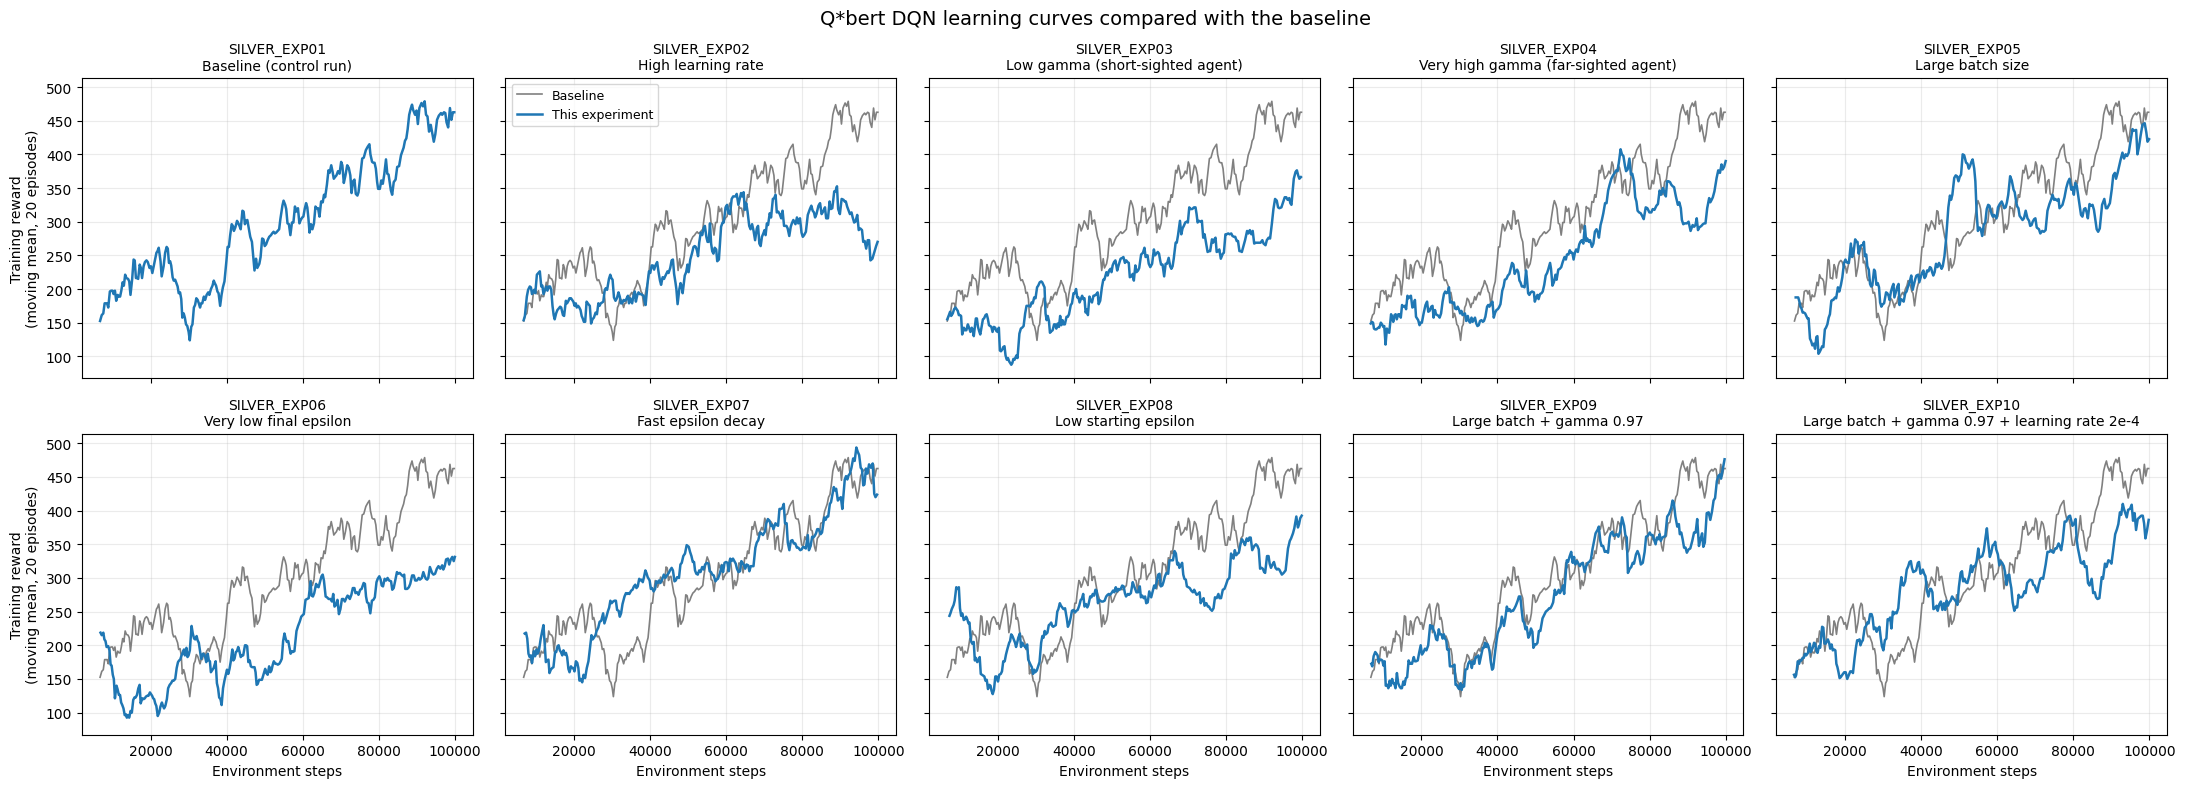

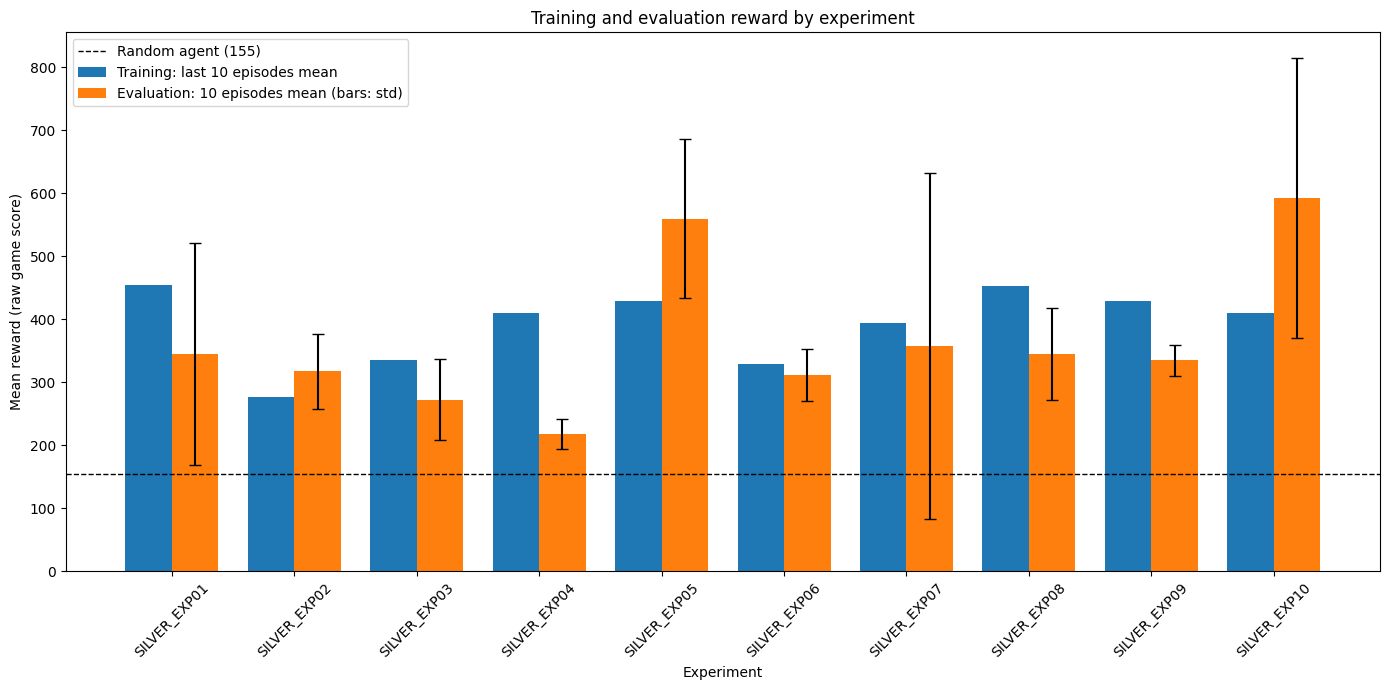

Saved: /content/drive/MyDrive/dqn-experiments-silver/plots/silver/silver_learning_curves.png
Saved: /content/drive/MyDrive/dqn-experiments-silver/plots/silver/silver_training_vs_evaluation.png


In [30]:
import matplotlib.pyplot as plt

MOVING_WINDOW = 20


def learning_curve(experiment_id):
    episodes = pd.read_csv(RESULTS_DIR / experiment_id / "episodes.csv")
    moving_mean = episodes["reward"].rolling(MOVING_WINDOW).mean()
    return episodes["total_steps"], moving_mean


baseline_id = EXPERIMENTS[0]["experiment_id"]
plotted_ids = list(training_results_df["Experiment"])

fig, axes = plt.subplots(2, 5, figsize=(22, 8), sharex=True, sharey=True)

for axis, experiment in zip(axes.flat, EXPERIMENTS):
    experiment_id = experiment["experiment_id"]
    axis.set_title(f"{experiment_id}\n{DESCRIPTIONS[experiment_id]}", fontsize=10)
    axis.grid(alpha=0.25)

    if baseline_id in plotted_ids and experiment_id != baseline_id:
        steps, curve = learning_curve(baseline_id)
        axis.plot(steps, curve, color="gray", linewidth=1.2, label="Baseline")

    if experiment_id in plotted_ids:
        steps, curve = learning_curve(experiment_id)
        axis.plot(steps, curve, color="tab:blue", linewidth=1.8, label="This experiment")
    else:
        axis.text(0.5, 0.5, "Not run yet", ha="center", va="center",
                  transform=axis.transAxes)

for axis in axes[-1]:
    axis.set_xlabel("Environment steps")
for axis in axes[:, 0]:
    axis.set_ylabel(f"Training reward\n(moving mean, {MOVING_WINDOW} episodes)")

axes.flat[1].legend(loc="upper left", fontsize=9)
fig.suptitle("Q*bert DQN learning curves compared with the baseline", fontsize=14)
fig.tight_layout()

learning_curves_path = PLOTS_DIR / f"{MEMBER}_learning_curves.png"
fig.savefig(learning_curves_path, dpi=200, bbox_inches="tight")
plt.show()

# ---- Training vs evaluation ----
comparison_df = final_results_df.sort_values("Experiment")
positions = range(len(comparison_df))
width = 0.38

plt.figure(figsize=(14, 7))
plt.bar(
    [p - width / 2 for p in positions],
    comparison_df["Last 10 Mean Reward"],
    width=width, label="Training: last 10 episodes mean",
)
plt.bar(
    [p + width / 2 for p in positions],
    comparison_df["Evaluation Mean Reward"],
    yerr=comparison_df["Evaluation Std Reward"], capsize=4,
    width=width, label=f"Evaluation: {EVAL_EPISODES} episodes mean (bars: std)",
)
plt.axhline(RANDOM_MEAN_REWARD, color="black", linestyle="--", linewidth=1,
            label=f"Random agent ({RANDOM_MEAN_REWARD:.0f})")
plt.title("Training and evaluation reward by experiment")
plt.xlabel("Experiment")
plt.ylabel("Mean reward (raw game score)")
plt.xticks(list(positions), comparison_df["Experiment"], rotation=45)
plt.legend()
plt.tight_layout()

comparison_plot_path = PLOTS_DIR / f"{MEMBER}_training_vs_evaluation.png"
plt.savefig(comparison_plot_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved:", learning_curves_path)
print("Saved:", comparison_plot_path)

# 13. Experiment results table

Creates `SilverHyperparameter_experiment_results.md` in the format the assignment asks for. The numbers come straight from the runs above. The "Observed behaviour" notes and the interpretation section are completed after studying the results and plots.

In [31]:
def format_number(value):
    """Plain text for a hyperparameter value, e.g. 0.0001, 1.0 or 100000."""
    if isinstance(value, float) and value < 0.001:
        return f"{value:.6f}".rstrip("0")
    return str(value)


results_by_id = {row["Experiment"]: row for _, row in final_results_df.iterrows()}

table_lines = [
    "| Experiment | Learning rate | Gamma | Batch size | Epsilon start "
    "| Epsilon end | Epsilon decay (steps) | Observed behaviour |",
    "| --- | --- | --- | --- | --- | --- | --- | --- |",
]

for experiment in EXPERIMENTS:
    experiment_id = experiment["experiment_id"]
    row = results_by_id.get(experiment_id)

    if row is None:
        observed = "Not run yet."
    else:
        observed = (
            f"{DESCRIPTIONS[experiment_id]}. "
            f"Training: {row['Episodes']} episodes, last-10 mean reward "
            f"{row['Last 10 Mean Reward']:.1f} at epsilon "
            f"{row['Final Training Epsilon']:.2f}. "
            f"Greedy evaluation: mean reward {row['Evaluation Mean Reward']:.1f} "
            f"(std {row['Evaluation Std Reward']:.1f}, "
            f"min {row['Minimum Reward']:.0f}, max {row['Maximum Reward']:.0f}), "
            f"mean episode length {row['Mean Episode Length']:.0f} steps, "
            f"rank {row['Evaluation Rank']} of {len(final_results_df)}."
        )

    cells = [experiment_id] + [
        format_number(experiment[name]) for name in HYPERPARAMETERS
    ] + [observed]
    table_lines.append("| " + " | ".join(cells) + " |")

ranking_lines = [
    "| Rank | Experiment | Evaluation mean reward | Std | Min | Max "
    "| Mean episode length | Training last-10 mean reward |",
    "| --- | --- | --- | --- | --- | --- | --- | --- |",
]

for _, row in final_results_df.iterrows():
    ranking_lines.append(
        f"| {row['Evaluation Rank']} | {row['Experiment']} "
        f"| {row['Evaluation Mean Reward']:.1f} | {row['Evaluation Std Reward']:.1f} "
        f"| {row['Minimum Reward']:.0f} | {row['Maximum Reward']:.0f} "
        f"| {row['Mean Episode Length']:.0f} | {row['Last 10 Mean Reward']:.1f} |"
    )

devices = ", ".join(sorted(set(training_results_df["Training Device"])))

report = f"""# {MEMBER.capitalize()}: Hyperparameter Experiment Results

Member name: {MEMBER_FULL_NAME}

Environment: `ALE/Qbert-v5`. All numbers below come from actual runs.

## Setup

- Training budget: {TOTAL_STEPS:,} environment steps per experiment, seed {SEED}.
- Training device: {devices} (Google Colab).
- Fixed settings: replay capacity 20,000, learning starts at 2,000 steps, one update every 4 steps, target network sync every 2,000 steps, linear epsilon decay, reward clipping on, Double DQN off.
- Baseline: learning rate {format_number(BASELINE['learning_rate'])}, gamma {BASELINE['gamma']}, batch size {BASELINE['batch_size']}, epsilon {BASELINE['epsilon_start']} to {BASELINE['epsilon_end']} over {BASELINE['epsilon_decay']:,} steps.
- Evaluation: each model played {EVAL_EPISODES} episodes (seeds {EVAL_SEED} to {EVAL_SEED + EVAL_EPISODES - 1}) with greedy actions (epsilon = 0).
- Reference: a random agent on the same episodes scored a mean reward of {RANDOM_MEAN_REWARD:.1f} (mean length {RANDOM_MEAN_LENGTH:.0f} steps).

## Experiment table

{chr(10).join(table_lines)}

## Evaluation ranking

{chr(10).join(ranking_lines)}

Best configuration in evaluation: `{best_row['Experiment']}` ({best_row['Evaluation Mean Reward']:.1f}).
Worst configuration in evaluation: `{worst_row['Experiment']}` ({worst_row['Evaluation Mean Reward']:.1f}).

## Plots

- `plots/{MEMBER}/{MEMBER}_learning_curves.png`: training reward of each experiment against the baseline.
- `plots/{MEMBER}/{MEMBER}_training_vs_evaluation.png`: training and evaluation reward by experiment.
- `plots/{MEMBER}/{MEMBER.upper()}_EXPxx.png`: reward, episode length and loss for each experiment.

## Interpretation

To be completed after studying the results: which hyperparameters improved or harmed performance, and the justification for the final configuration.

## Limitations

Each configuration was trained once with a single seed and evaluated on {EVAL_EPISODES} episodes, so small differences between experiments may be due to chance.

## Reproducibility

Each experiment's exact configuration is in `results/{MEMBER}/{MEMBER.upper()}_EXPxx/summary.json`, with episode logs in `episodes.csv`, update logs in `training_updates.csv` and final weights in `models/{MEMBER}/`. The ten configurations are in `{MEMBER}_experiments.json`.
"""

report_path = DRIVE_ROOT / f"{MEMBER.capitalize()}Hyperparameter_experiment_results.md"
report_path.write_text(report, encoding="utf-8")

print("Results table created:", report_path)
print(f"Experiments included: {len(final_results_df)}/10")

Results table created: /content/drive/MyDrive/dqn-experiments-silver/SilverHyperparameter_experiment_results.md
Experiments included: 10/10


# 14. Package the files for GitHub

Builds a zip whose folders match the group repository (`models/silver/`, `results/silver/`, `plots/silver/`), so it can be unzipped straight into the repo folder and committed.

The intermediate `checkpoint_step_*.pth` files stay on Google Drive only. They are large and are excluded by the repo's `.gitignore`.

Run this once all ten experiments are finished.

In [32]:
import shutil
import zipfile

assert len(final_results_df) == 10, (
    f"Only {len(final_results_df)}/10 experiments are finished and evaluated."
)

PACKAGE_DIR = DRIVE_ROOT / f"{MEMBER}_repo_files"
if PACKAGE_DIR.exists():
    shutil.rmtree(PACKAGE_DIR)


def copy_into_package(source, relative_destination):
    destination = PACKAGE_DIR / relative_destination
    destination.parent.mkdir(parents=True, exist_ok=True)
    shutil.copy2(source, destination)


for experiment in EXPERIMENTS:
    experiment_id = experiment["experiment_id"]

    copy_into_package(
        MODELS_DIR / f"{experiment_id}.pth",
        Path("models") / MEMBER / f"{experiment_id}.pth",
    )
    copy_into_package(
        PLOTS_DIR / f"{experiment_id}.png",
        Path("plots") / MEMBER / f"{experiment_id}.png",
    )
    for name in ("summary.json", "episodes.csv", "training_updates.csv"):
        copy_into_package(
            RESULTS_DIR / experiment_id / name,
            Path("results") / MEMBER / experiment_id / name,
        )

for path in (training_csv_path, evaluation_episodes_path, evaluation_summary_path,
             random_baseline_path, final_results_path):
    copy_into_package(path, Path("results") / MEMBER / path.name)

for path in (learning_curves_path, comparison_plot_path):
    copy_into_package(path, Path("plots") / MEMBER / path.name)

copy_into_package(CONFIG_FILE, CONFIG_FILE.name)
copy_into_package(report_path, report_path.name)

zip_path = DRIVE_ROOT / f"{MEMBER}_repo_files.zip"

with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zip_file:
    for file_path in sorted(PACKAGE_DIR.rglob("*")):
        if file_path.is_file():
            zip_file.write(file_path, arcname=file_path.relative_to(PACKAGE_DIR))

file_count = sum(1 for p in PACKAGE_DIR.rglob("*") if p.is_file())
print("Files packaged:", file_count)
print("ZIP created:", zip_path)
print("ZIP size:", round(zip_path.stat().st_size / (1024 * 1024), 1), "MB")

try:
    from google.colab import files
    files.download(str(zip_path))
except ImportError:
    pass

Files packaged: 59
ZIP created: /content/drive/MyDrive/dqn-experiments-silver/silver_repo_files.zip
ZIP size: 69.1 MB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>